# MedSkel AI — Day 1: CNN proof of start

**University project:** retinal blood-vessel segmentation using a small U-Net CNN.

**Research question:** Can a CNN locate vessels in retinal photographs, so a later geometry stage can estimate vessel length, width and branching?

**Original references:** Ronneberger et al. (2015), *U-Net* — https://arxiv.org/abs/1505.04597 ; Jin et al. (2022), *FIVES* — https://doi.org/10.1038/s41597-022-01564-3 .

**Honest scope today:** (1) display a retinal image, (2) construct and test the network, and (3) run an optimizer step on **actual expert vessel masks only if FIVES data have been downloaded**. The model is **not clinically validated** and does **not diagnose disease**.

This notebook is separate from the existing MedSkel GitHub repository; it does not edit the repository or test set.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from torch.nn import functional as F

print("PyTorch version:", torch.__version__)
print("Available accelerator:", "CUDA" if torch.cuda.is_available() else "CPU")
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PyTorch version: 2.10.0+cpu
Available accelerator: CPU


## 1 — What is a retinal fundus image?

A color photograph of the back of the eye. We want a **binary vessel mask**: white for vessel pixels, black for background.

Until you download FIVES, we use the **sample retina photograph from scikit-image only for display**. This is not a training label.

/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


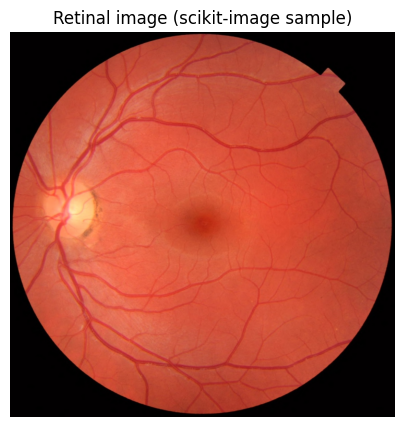

In [2]:
from skimage.data import retina
fundus = retina()
plt.figure(figsize=(5,5))
plt.imshow(fundus)
plt.title("Retinal image (scikit-image sample)")
plt.axis("off")
plt.show()

## 2 — Build a real (small) U-Net

The encoder applies convolutions and pooling; the decoder upsamples and reuses earlier features through **skip connections**.

- `Conv2d(3, 8, 3, padding=1)` takes an RGB image and learns eight feature maps.
- `ReLU` introduces nonlinearity.
- `MaxPool2d(2)` halves height and width.
- The last output has one channel of **logits**, one for each pixel. `sigmoid` converts logits to vessel probabilities.

The code below uses only PyTorch, not a pretrained model.

In [3]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.net(x)

class SmallUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = ConvBlock(3, 8)
        self.enc2 = ConvBlock(8, 16)
        self.bridge = ConvBlock(16, 32)
        self.pool = nn.MaxPool2d(2)
        self.dec2 = ConvBlock(32 + 16, 16)
        self.dec1 = ConvBlock(16 + 8, 8)
        self.out = nn.Conv2d(8, 1, kernel_size=1)

    def forward(self, x):
        a = self.enc1(x)
        b = self.enc2(self.pool(a))
        c = self.bridge(self.pool(b))
        d = F.interpolate(c, size=b.shape[-2:], mode="bilinear", align_corners=False)
        d = self.dec2(torch.cat([d, b], dim=1))
        d = F.interpolate(d, size=a.shape[-2:], mode="bilinear", align_corners=False)
        d = self.dec1(torch.cat([d, a], dim=1))
        return self.out(d)

model = SmallUNet().to(DEVICE)
x_demo = torch.zeros(1, 3, 128, 128, device=DEVICE)
with torch.no_grad():
    y_demo = model(x_demo)
print("Input tensor:", tuple(x_demo.shape))
print("Output tensor:", tuple(y_demo.shape))
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))
assert y_demo.shape == (1, 1, 128, 128)

Input tensor: (1, 3, 128, 128)
Output tensor: (1, 1, 128, 128)
Trainable parameters: 29761


## 3 — Proof that backpropagation runs

A **synthetic vessel-like drawing** is used *only to test the math and software*. It does not prove that the model can identify retinal vessels.

This checks that loss, gradients and the optimizer all work. Real retinal training is the next section.

In [4]:
# A tiny handmade test image and pixel mask — software test, not retinal training evidence.
from PIL import ImageDraw
canvas = Image.new("L", (64, 64), 0)
brush = ImageDraw.Draw(canvas)
brush.line([(8, 46), (28, 31), (51, 14)], fill=255, width=3)
brush.line([(28, 31), (50, 44)], fill=255, width=2)
target_np = np.array(canvas, dtype=np.float32) / 255.0
image_np = np.repeat(target_np[..., None], 3, axis=2)
image_t = torch.from_numpy(image_np.transpose(2, 0, 1)).unsqueeze(0).to(DEVICE)
target_t = torch.from_numpy(target_np).unsqueeze(0).unsqueeze(0).to(DEVICE)

model.train()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()
optimizer.zero_grad()
logits = model(image_t)
loss = criterion(logits, target_t)
loss.backward()
gradient_exists = any(p.grad is not None and p.grad.abs().sum().item() > 0 for p in model.parameters())
optimizer.step()
print("One training step: PASS" if gradient_exists else "One training step: FAIL")
print("Training loss:", round(loss.item(), 4))
assert gradient_exists and torch.isfinite(loss)

One training step: PASS
Training loss: 0.7329


## 4 — Load FIVES expert annotations (real CNN training)

Get the original [FIVES dataset](https://doi.org/10.6084/m9.figshare.19688169) and place it outside GitHub. The paper describes an original `train/Original/` and `train/Ground Truth/` layout. Set the path below to your extracted dataset root.

**Important:** Use images from `train` only for today's demonstration. Do not touch the official `test` images. FIVES subject IDs need to be checked before a final scientific split, since 800 images come from 573 subjects.

If FIVES is not present, the next cell prints the expected location and skips training rather than inventing results.

In [5]:
# CHANGE THIS PATH once the official FIVES dataset has been downloaded.
FIVES_ROOT = Path("FIVES")
train_dir = FIVES_ROOT / "train"
img_dir = train_dir / "Original"
mask_dir = train_dir / "Ground Truth"

# Accept minor capitalization variants in extracted official zip.
if train_dir.exists():
    for p in train_dir.iterdir():
        if p.is_dir() and p.name.lower().replace(" ", "") in {"groundtruth", "groundtruths"}:
            mask_dir = p
        if p.is_dir() and p.name.lower() == "original":
            img_dir = p
pairs = [(p, mask_dir / p.name) for p in sorted(img_dir.glob("*.png")) if (mask_dir / p.name).exists()]
print("Matching official FIVES training image/mask pairs found:", len(pairs))
if not pairs:
    print("NOT TRAINED on FIVES yet. Download it, set FIVES_ROOT, then rerun this section.")

Matching official FIVES training image/mask pairs found: 0
NOT TRAINED on FIVES yet. Download it, set FIVES_ROOT, then rerun this section.


In [6]:
def load_pair(image_path, mask_path, size=128):
    with Image.open(image_path) as im:
        image = np.asarray(im.convert("RGB").resize((size, size), Image.Resampling.BILINEAR), dtype=np.float32) / 255.0
    with Image.open(mask_path) as mk:
        mask = np.asarray(mk.convert("L").resize((size, size), Image.Resampling.NEAREST), dtype=np.float32)
    mask = (mask > 127).astype(np.float32)
    image_tensor = torch.from_numpy(image.transpose(2, 0, 1))
    mask_tensor = torch.from_numpy(mask[None])
    return image, mask, image_tensor, mask_tensor

if pairs:
    image, gt, _, _ = load_pair(*pairs[0])
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(image); ax[0].set_title("FIVES retinal image")
    ax[1].imshow(gt, cmap="gray", vmin=0, vmax=1); ax[1].set_title("Expert vessel annotation")
    for a in ax: a.axis("off")
    plt.show()

## 5 — Optional tiny real-data training check

If you provided FIVES, the cell below trains on just **two training images for four optimizer steps**, to check that image loading and the training loop execute. This is *not a trained or evaluated model*: it is far too little data and never uses the official test set.

For the next milestone, use a proper train/validation split, more epochs, report per-image Dice, and retain high resolution so small vessels are not lost.

In [7]:
if pairs:
    batches = [load_pair(*pair)[2:] for pair in pairs[:2]]
    model.train()
    for step in range(4):
        for image_tensor, mask_tensor in batches:
            x = image_tensor.unsqueeze(0).to(DEVICE)
            y = mask_tensor.unsqueeze(0).to(DEVICE)
            optimizer.zero_grad()
            output = model(x)
            training_loss = criterion(output, y)
            training_loss.backward()
            optimizer.step()
        print(f"Step {step + 1}/4: training loss {training_loss.item():.4f}")
    print("Tiny-batch FIVES training test: completed (NOT a validated model)")
else:
    print("Skipped: FIVES image/mask pairs are not installed locally.")

Skipped: FIVES image/mask pairs are not installed locally.


## 6 — What to tell the professor

> My project is **MedSkel AI: retinal blood vessel segmentation with U-Net**. The input is a retinal photograph, and the CNN learns a binary vessel mask from expert annotations in FIVES. I began with the original U-Net research paper, implemented the convolutional encoder/decoder with skip connections, and checked the network's output dimensions and backpropagation. The next step is training on the full training split, evaluating on held-out annotated images, and using my existing geometry-based MedSkel research to measure vessels.

**Show evidence honestly:** If you have not downloaded FIVES, say the model architecture and gradient test work, but **retinal training has not started**. If you completed Section 5, say it was only a two-image software sanity check.

### Planned scientific evaluation

- Segmentation: Dice, IoU, precision and recall on a truly held-out split.
- Geometry: compare centerline extraction and pixel-space length against simple thinning and existing MedSkel.
- Scope: initial research prototype, not a diagnosis or validated clinical measurement tool.

**Repository is unchanged.** This notebook is a starting artifact for class preparation.